# 01. Exploratory data analysis (action item S2)

This notebook checks that the numbers in the proposal come from the raw data, and produces the two proposal figures (Figure 1a, Figure 1b).

The missing-BMI investigation (D1, D2) is in `02_missing_bmi.ipynb`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from statsmodels.stats.proportion import confint_proportions_2indep, proportion_confint

from src.config import ALPHA, FIGURES, N_BOOT, SEED, TABLES
from src.data import load_raw

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
RECORDED, MISSING = "#2a78d6", "#eb6834"  # colour follows the group in every figure
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11,
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 200,
})

df = load_raw()
df["bmi_missing"] = df["bmi"].isna().astype(int)

## Proposal numbers against the raw data

Each number stated in section 3 of the proposal is recomputed and compared at the precision the proposal used. The cell stops with an error if any number fails to match.

In [2]:
strokes = int(df["stroke"].sum())
miss, rec = df[df["bmi_missing"] == 1], df[df["bmi_missing"] == 0]
smoke = df["smoking_status"].value_counts()
under18 = df[df["age"] < 18]

# (item, value stated in the proposal, value from the data, decimals the proposal used)
checks = [
    ("Rows", 5110, len(df), 0),
    ("Strokes", 249, strokes, 0),
    ("Stroke rate, %", 4.87, 100 * strokes / len(df), 2),
    ("BMI missing", 201, int(df["bmi"].isna().sum()), 0),
    ("BMI missing, %", 3.9, 100 * df["bmi"].isna().mean(), 1),
    ("Stroke rate, BMI missing, %", 19.9, 100 * miss["stroke"].mean(), 1),
    ("Stroke rate, BMI recorded, %", 4.3, 100 * rec["stroke"].mean(), 1),
    ("Strokes among BMI missing", 40, int(miss["stroke"].sum()), 0),
    ("Share of strokes lost if dropped, %", 16, 100 * miss["stroke"].sum() / strokes, 0),
    ("Smoking: never smoked", 1892, int(smoke["never smoked"]), 0),
    ("Smoking: formerly smoked", 885, int(smoke["formerly smoked"]), 0),
    ("Smoking: smokes", 789, int(smoke["smokes"]), 0),
    ("Smoking: Unknown", 1544, int(smoke["Unknown"]), 0),
    ("Smoking Unknown, %", 30.2, 100 * smoke["Unknown"] / len(df), 1),
    ("Patients under 18", 856, len(under18), 0),
    ("Patients under 18, %", 16.8, 100 * len(under18) / len(df), 1),
    ("Strokes under 18", 2, int(under18["stroke"].sum()), 0),
    ("Gender 'Other'", 1, int((df["gender"] == "Other").sum()), 0),
    ("BMI > 60", 13, int((df["bmi"] > 60).sum()), 0),
    ("BMI maximum", 97.6, df["bmi"].max(), 1),
    ("BMI minimum", 10.3, df["bmi"].min(), 1),
    ("Age maximum", 82, df["age"].max(), 0),
    ("Age minimum", 0.08, df["age"].min(), 2),
    ("Glucose minimum", 55, df["avg_glucose_level"].min(), 0),
    ("Glucose maximum", 272, df["avg_glucose_level"].max(), 0),
]
check = pd.DataFrame(
    [(i, p, round(v, d), round(v, d) == p) for i, p, v, d in checks],
    columns=["item", "proposal", "reproduced", "match"],
)
check.to_csv(TABLES / "eda_proposal_check.csv", index=False)
assert check["match"].all(), check[~check["match"]]
display(check)
print(f"{check['match'].sum()} of {len(check)} proposal numbers reproduced.")

,item,proposal,reproduced,match
0,Rows,5110.00,5110.00,True
1,Strokes,249.00,249.00,True
2,"Stroke rate, %",4.87,4.87,True
3,BMI missing,201.00,201.00,True
4,"BMI missing, %",3.90,3.90,True
5,"Stroke rate, BMI missing, %",19.90,19.90,True
6,"Stroke rate, BMI recorded, %",4.30,4.30,True
7,Strokes among BMI missing,40.00,40.00,True
8,"Share of strokes lost if dropped, %",16.00,16.00,True
9,Smoking: never smoked,1892.00,1892.00,True


25 of 25 proposal numbers reproduced.


## Stroke rate by missing information (proposal Figure 1b)

Intervals are Wilson intervals for each rate, Newcombe intervals for risk differences, and log-method intervals for risk ratios.

In [3]:
def rate_row(label, group, sub):
    n, k = len(sub), int(sub["stroke"].sum())
    lo, hi = proportion_confint(k, n, alpha=ALPHA, method="wilson")
    return {"variable": label, "group": group, "n": n, "strokes": k,
            "rate_pct": 100 * k / n, "ci_low_pct": 100 * lo, "ci_high_pct": 100 * hi}

smoke_unknown = df["smoking_status"] == "Unknown"
rates = pd.DataFrame([
    rate_row("BMI", "Recorded", rec),
    rate_row("BMI", "Missing", miss),
    rate_row("Smoking status", "Known", df[~smoke_unknown]),
    rate_row("Smoking status", "Unknown", df[smoke_unknown]),
])
rates.to_csv(TABLES / "eda_stroke_rate_by_missingness.csv", index=False)
display(rates.round(2))

def contrast(a, b):
    """Risk difference (Newcombe) and risk ratio (log method) for group a vs group b."""
    k1, n1, k0, n0 = a["stroke"].sum(), len(a), b["stroke"].sum(), len(b)
    rd = confint_proportions_2indep(k1, n1, k0, n0, method="newcomb", compare="diff", alpha=ALPHA)
    rr = confint_proportions_2indep(k1, n1, k0, n0, method="log", compare="ratio", alpha=ALPHA)
    return {"risk_diff_pct": 100 * (k1 / n1 - k0 / n0), "rd_low_pct": 100 * rd[0], "rd_high_pct": 100 * rd[1],
            "risk_ratio": (k1 / n1) / (k0 / n0), "rr_low": rr[0], "rr_high": rr[1]}

contrasts = pd.DataFrame([
    {"comparison": "BMI missing vs recorded", **contrast(miss, rec)},
    {"comparison": "Smoking Unknown vs known", **contrast(df[smoke_unknown], df[~smoke_unknown])},
])
contrasts.to_csv(TABLES / "eda_missingness_contrasts.csv", index=False)
display(contrasts.round(2))

,variable,group,n,strokes,rate_pct,ci_low_pct,ci_high_pct
0,BMI,Recorded,4909,209,4.26,3.73,4.86
1,BMI,Missing,201,40,19.90,14.97,25.96
2,Smoking status,Known,3566,202,5.66,4.95,6.47
3,Smoking status,Unknown,1544,47,3.04,2.30,4.02


,comparison,risk_diff_pct,rd_low_pct,rd_high_pct,risk_ratio,rr_low,rr_high
0,BMI missing vs recorded,15.64,10.67,21.73,4.67,3.44,6.36
1,Smoking Unknown vs known,-2.62,-3.72,-1.41,0.54,0.39,0.73


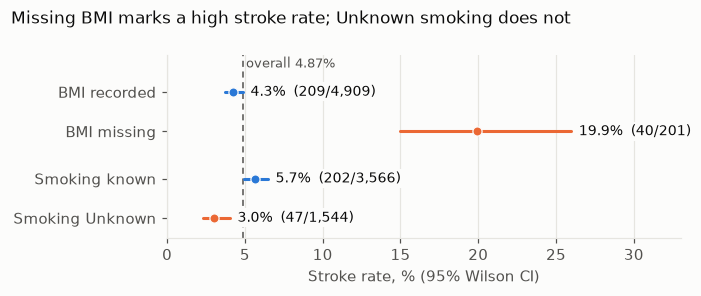

In [4]:
overall = 100 * df["stroke"].mean()
fig, ax = plt.subplots(figsize=(6.4, 2.7))
ypos = [3, 2, 0.8, -0.2]
colors = [RECORDED, MISSING, RECORDED, MISSING]
for y, c, (_, r) in zip(ypos, colors, rates.iterrows()):
    ax.plot([r.ci_low_pct, r.ci_high_pct], [y, y], color=c, lw=2, solid_capstyle="round")
    ax.plot(r.rate_pct, y, "o", ms=6, color=c, mec=SURFACE, mew=0.8, zorder=3)
    ax.text(r.ci_high_pct + 0.5, y, f"{r.rate_pct:.1f}%  ({r.strokes}/{r.n:,})", va="center", fontsize=9,
            bbox=dict(fc=SURFACE, ec="none", pad=1.5), zorder=4)
ax.axvline(overall, color=INK_2, lw=1, ls=(0, (4, 3)), zorder=1)
ax.text(overall + 0.2, 3.62, f"overall {overall:.2f}%", color=INK_2, fontsize=8.5)
ax.set_yticks(ypos, ["BMI recorded", "BMI missing", "Smoking known", "Smoking Unknown"])
ax.set_ylim(-0.7, 3.95)
ax.set_xlim(0, 33)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Stroke rate, % (95% Wilson CI)")
fig.suptitle("Missing BMI marks a high stroke rate; Unknown smoking does not", x=0.02, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "eda_stroke_rate_by_missingness.png")
plt.show()

**Reading the figure.** Patients with missing BMI had a stroke rate of 19.9% (95% CI 15.0 to 26.0), against 4.3% (3.7 to 4.9) with BMI recorded. That is a risk difference of 15.6 percentage points (10.7 to 21.7) and a risk ratio of 4.67 (3.44 to 6.36). Dropping these 201 patients would remove 40 of the 249 strokes, so complete-case analysis works on a lower-risk sample.

Patients with Unknown smoking status had a lower crude rate than patients with known status: 3.0% against 5.7%, a risk ratio of 0.54 (0.39 to 0.73). These are unadjusted rates. `02_missing_bmi.ipynb` shows that the Unknown category has an adjusted odds ratio for stroke close to 1.

## Glucose distribution (proposal Figure 1a)

Peak locations come from a Gaussian kernel density estimate. They are descriptive locations only. Fitting and testing distributions is Track 2's work (E1 to E3).

Density peaks (mg/dL): [ 83.7 207.5]
Glucose > 150 mg/dL: 730 of 5110 = 14.3% (95% Wilson CI 13.4 to 15.3)


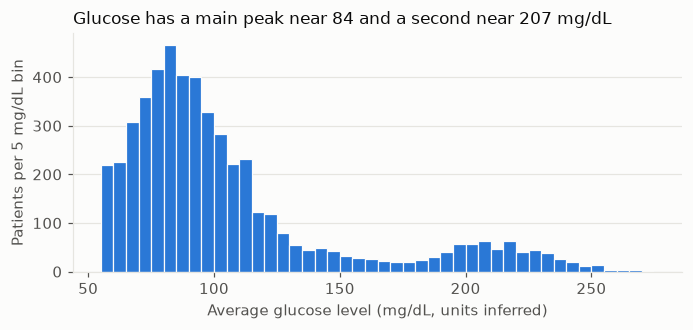

In [5]:
g = df["avg_glucose_level"]
grid = np.linspace(g.min(), g.max(), 2000)
density = stats.gaussian_kde(g)(grid)
from scipy.signal import find_peaks
peak_idx, _ = find_peaks(density, prominence=density.max() * 0.02)
peaks = grid[peak_idx]
above150 = (g > 150).sum()
lo150, hi150 = proportion_confint(above150, len(g), alpha=ALPHA, method="wilson")
print("Density peaks (mg/dL):", np.round(peaks, 1))
print(f"Glucose > 150 mg/dL: {above150} of {len(g)} = {100 * above150 / len(g):.1f}% "
      f"(95% Wilson CI {100 * lo150:.1f} to {100 * hi150:.1f})")

fig, ax = plt.subplots(figsize=(6.4, 3.1))
ax.hist(g, bins=np.arange(55, 280, 5), color=RECORDED, edgecolor=SURFACE, linewidth=0.8)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Average glucose level (mg/dL, units inferred)")
ax.set_ylabel("Patients per 5 mg/dL bin")
ax.set_title(f"Glucose has a main peak near {peaks[0]:.0f} and a second near {peaks[-1]:.0f} mg/dL")
fig.tight_layout()
fig.savefig(FIGURES / "eda_glucose_histogram.png")
plt.show()

**Reading the figure.** Glucose has a main peak near 84 mg/dL and a second, smaller peak near 207 mg/dL. This matches the proposal's description of a main group at 80 to 90 and a second group at 200 to 230 mg/dL. The second peak is the feature a single log-normal or Gamma curve will have trouble fitting. In total, 14.3% of patients (95% CI 13.4 to 15.3) have glucose above 150 mg/dL. The file does not state glucose units, so mg/dL is inferred from the range of values.